# 📘 2.1 Optimisation, Profiling and Machine Performance
### FLOPS, BYTES, Performance Limits, Arithmetic Intensity, Timing and Profiling of Codes.

Introduce limits to the performance that can be extracted from a given computer, explain how to determine if the performance of your code will be limited by processor speed or memory access, and demonstrate how you can use timing routines and profiling tools to help identify performance issue in a code.

---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * Appreciate why numerical performance matters.
> * Understand how performance can be limited by either processor speed or memory bandwith.
> * Be able to estimate the theoretical compute performance and machine balance point.
> * Understand the concept of Arithmetic Intensity and be able to estimate it for numerical calculations.
> * Carry out empirical testing of System and Code Performance
> * Use basic profiling applications to identify potential bottlenecks in a code.


## 📂 2.1.1 Why Engineers Need to Worry About Numerical Performance

---

As pointed out in the [introduction to this unit](https://colab.research.google.com/drive/1ItBNRruYfB9j_7k5yu8nuC3QAVedeSWV?usp=playground), not all codes are created equally. While two different implementations may arrive at a common solution (at least to within numerical accuracy - more on that latter), one may do so in a far shorter time and consume far less computational resources and energy in doing so.

A user working on their own local machine, needs to consider whether their machine has enough memory to store the data required by their problem, how many hours it might take to complete, and whether they can do anything else while the problem in running. It doesn't take much for desired engineering simulations to grow to a size that required 100-500 GB of Memory and days of compute time.

In engineering, you will find that you quickly reach the limits of what can be done on your own computer. This might be because the mesh you have generated for your calcultion required 1 Terabyte of memory, or because the calculation has been running for 3 days and is still no where near finishing. When this occurs, you need to ask for time on a bigger machine, which might cost you \$0.05 per core per hour. **How much money would you save your company if you could half the time it takes to complet your calculation?**

> ### 💬 Aside
> Direct Numerical Simulation (DNS) of even low Reynolds number flows require simultaneous evaluation of millions of data points. These simulations can easily require over 50 Million hours to compute. Of course, we have to do this in parallel on 1000s of CPUs at the same time.

The cost of a computation are not just the costs associated with the hardware or the price to access the required cloud compute and data storage. Computer require energy and cooling, meaning that depending on the source of their electrical supply, these systems can provide an non-neglible contribution to global warming and require a substantial water supply to keep them cool.

In the past decade, there has been growing move towards ensuring <font color="green">Green Computing</font>. Many of you may have heard reference to the [TOP500](https://www.top500.org/lists/top500/2025/11/$0) - a list of the 500 most powerful computers in the the world. What you might not have heard about is the similar [GREEN500](https://www.top500.org/lists/green500/2025/11/$0), in which the  systems of the TOP500 are ranked by how much computational performance they deliver per Watt of electrical power they consume.

> ### 💬 Aside
> When it launched in 2022, Australia's Setonix Super Computer Australia’s Setonix was the fourth greenest supercomputer in the world. It was the most powerful in the Southern Hemisphere, 15th in the World.
> "The energy efficiency of Setonix is made possible by the adoption of the latest AMD CPU and GPU technology, together with innovative direct liquid cooling of all system components. In addition to that, the system is cooled by a geothermal solution, pioneered by Australia’s national science agency CSIRO, saving approximately 7 million litres of water every year that might otherwise be wasted, and powered by a 120kW solar panel system, which helps offset the centre’s carbon footprint." - https://pawsey.org.au/australias-setonix-ranking/

Rapid growth of AI and associated Data Centres has triggered a growth concern about how we will meet the growing energy and water demands, and some would question if these costs are even justified. A recent paper titled *The carbon and water footprints of data centers and what this could mean for artificial intelligence* estimated that current "AI systems may have a carbon footprint equivalent to that of New York City in 2025, while their water footprint could be in the range of the global annual consumption of bottled water" - https://doi.org/10.1016/j.patter.2025.101430

> ### ⚠️ Point of note
> There are real economic and environmental costs assocciated with computing and as Engineers we have a moral obligation to be responsible and efficient users of these systems.


## 📂 2.1.2 Basic Computer System Topology

---

In the previous exercise, you may recall we tried to build a tool called hwloc, from it's public GitHub repository. Unfortunately the Colab enrivonment doesn't allow us to do this as Colab has some strictions on it compute runtimes. However, each runtime is still running on a Linux backend, so we can make use of Linux package managers and a range of other tools.

> ### 📖 Definition
> **Package manager** is Linux (can get similar onces of Mac OS) is software handles the installation, updates, and removal, of software on your machine. It automates everything needed to manage software packages — including path to downloading them, verifying metadata, resolving and handle library dependencies, and keeping the system consistent.
>
> The benefit is that if I want to install a certain tool, the manager will automatically check if I already have the other libraries I need to run it, and will download and link these so that I don't have to.


First let's use this to see what packages we already have installed. The most common is probably APT, and that is also the one that runs on Colab. Python has something similar in `pip`.

> ### 🧾 Instructions
> 1. run `!apt list` to see a list of the packages that are already install on the Colab runtime

In [ ]:
!apt list

Streaming output truncated to the last 5000 lines.
speechd-el/jammy 2.11-2 all
speechd-up/jammy 0.5~20110719-11 amd64
speedcrunch/jammy 0.12.0-5 amd64
speedometer/jammy 2.8-3 all
speedtest-cli/jammy 2.1.3-2 all
speex-doc/jammy 1.2~rc1.2-1.1ubuntu3 all
speex/jammy 1.2~rc1.2-1.1ubuntu3 amd64
spell/jammy 1.0-24.2 amd64
spellcast-doc/jammy 1.5+nmu2 all
spellcast/jammy 1.0-22 amd64
spellutils/jammy 0.7-8 amd64
spew/jammy 1.0.8-1build5 amd64
spf-tools-perl/jammy 2.9.0-5 all
spf-tools-python/jammy 2.0.14-2 all
spfquery/jammy 1.2.10-7.1ubuntu1 amd64
sphde-utils/jammy 1.4.0-2build1 amd64
sphinx-common/jammy 4.3.2-1 all
sphinx-doc/jammy 4.3.2-1 all
sphinx-intl/jammy 2.0.1-2 amd64
sphinx-rtd-theme-common/jammy 1.0.0+dfsg-1 all
sphinx-voxforge-hmm-en/jammy 0.1.1~daily20130301-0ubuntu1 all
sphinx-voxforge-lm-en/jammy 0.1.1~daily20130301-0ubuntu1 all
sphinxbase-utils/jammy 0.8+5prealpha+1-13build1 amd64
sphinxsearch/jammy 2.2.11-8 amd64
sphinxtrain/jammy 1.0.8+5prealpha+1-4 amd64
spi-tools/jammy 0.8

You will note that the output here is truncated to the last 5000 lines, which is why the list begins as 's'. This is basically everything needed on the backend. It also suggest that Google is using a version of Ubuntu Linux.

Let's add to list and install a new library *hwloc*

> 2. run `!sudo apt-get install hwloc`

> ### 🧩 Code Explanation
> `sudo` tells linux to run this command as a super user and give access that would not be avaliable to a normal user. Usually this would require a password, but not on Colab.

In [ ]:
!sudo apt-get install hwloc

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  hwloc
0 upgraded, 1 newly installed, 0 to remove and 3 not upgraded.
Need to get 223 kB of archives.
After this operation, 766 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 hwloc amd64 2.7.0-2ubuntu1 [223 kB]
Fetched 223 kB in 0s (834 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package hwloc.
(Reading database ... 118243 files and directories cur

You can now access hwloc commands outside of python, as below.

> 3. Run `lstopo` which lists the topology of the current system.

In [ ]:
!lstopo

Machine (13GB total)
  Package L#0
    NUMANode L#0 (P#0 13GB)
    L3 L#0 (55MB) + L2 L#0 (256KB) + L1d L#0 (32KB) + L1i L#0 (32KB) + Core L#0
      PU L#0 (P#0)
      PU L#1 (P#1)
  HostBridge
    PCI 00:03.0 (Other)
      Block "sda"
    PCI 00:04.0 (Ethernet)
    PCI 00:05.0 (Other)
    PCI 00:06.0 (Other)


You can view this graphically by first generating an image of the machine. The displaying this via the IPython display functions.

> 4. Run `lstopo --output-format png` to generate an image of the topology. Then display the generate png image as follows.

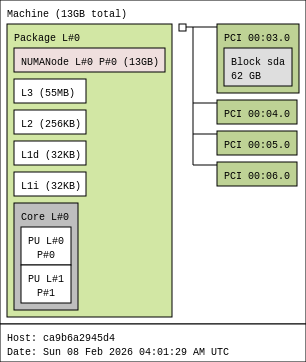

In [ ]:
# Generate a PNG of the topology
!lstopo --output-format png machine_view.png

# Display it in Jupyter
from IPython.display import Image
Image('machine_view.png')


So we can see that we have:
* 13 GB of Memory in Total, with the *NUMANode* being memory that is directly accessible to the host processors.
* L1i, L1d - Level 1 Memory *Cache* 32 KB (Fastest Memory) split into L1i - instructions and L1d - data
* L2 - Level 2 Memory *Cache* 256 KB
* L3 - Level 3 Memory *Cache* 55 MB

While the 13 GB is normal DRAM or Main Memory, the *cache* are small, ultra-fast memory lanes that feed directly into the processor. Memory exists in a hierachy. Level 1 is the fastest memory, located directly inside the CPU core. Level 2 is slower, but larger, and Level 3 is even slower, but larger still.

Each time the CPU needs to know what to do next, it looks to *L1i* and when it needs data it Looks to *L1d* cache. If it finds what it is looking for then it can continue running. If it doesn't, it must look to cache *L2*, then *L3*. Failing this, new data mush be fetched from the even slower main RAM, and copied into the buffer.

> **Why do we care?**
Well when we are using large data sets, such as in machine learning or engineering simulations, the limit it not always processor speed. If we have to move around a lot of data, performance can be limited by memory bandwidth. The more we exceed the cache limits the worse our performance.

> ### 📖 Definition
> **Memory Bandwidth:** is the rate at which data can be moved between memory and the CPU/GPU. Quoted as Bytes-per-second.

## 📂 2.1.3 Theoretical Maximum Computing Performance
---

Previously, we established the metric of [Floating Point Operations per Second (FLOPS/s)](https://colab.research.google.com/drive/1ItBNRruYfB9j_7k5yu8nuC3QAVedeSWV?usp=playground#scrollTo=7f1J1FJLTM0_) as a key parameter of interest for engineers who are interested in the speed a given calculation.

> There is a similar measure for **Integer Operations Per Second** (IOPS/s)., which is generally higher than FLOPS/s as integer calculation are less intensive. However, most numerical calculations will require floating point values.

We can estimate the maximum theoretical FLOPS/s ($F_T$) as

\begin{equation}
F_T = C_v \times f_c \times I_c  = \text{Virtual cores} \times \text{Clock Rate}\times \text{Instruction/Cycle}.\tag{2.1}
\end{equation}

The effective number of Virtual cores includes any hyperthreads ($H_T$) that might be part of the core, hence

\begin{equation}
C_v = C_h \times H_T = \text{Physical cores} \times \text{Hyperthreads}.\tag{2.2}
\end{equation}



The maximum number of instruction per cycle is a bit more complicated. It depends on the *vector unit width* ($VW$) we mentioned in Week 1, as well as the size of the data object (Word size) we are operation on $W_{bits}$ and the ability for a modern processor to perform a *Fused Multiplier Add*.

> ### 📖 Definition
> **Fused Multiplier Add (FMA):** is a fancy way of saying that the processor can do a multiplication and addition in the same step, i.e. $(a\times b) + c$. This is supported on most modern processors.

We can estimate the Instructions/Cycle as,

\begin{equation}
I_c = VW/W_{bits}\times F_{ops} = \text{Vector Unit Width / Word size} \times \text{Fused Operations}.\tag{2.3}
\end{equation}

### 🧪 Example - Theoretical Performance of Default Colab Runtime (June 2026)

Recall, we showed in the [Week 1.1](https://colab.research.google.com/drive/1ItBNRruYfB9j_7k5yu8nuC3QAVedeSWV?usp=playground#scrollTo=sKnNoHRIIWSG) that we can use `lscpu` to display information about our CPU. Consider the Machine we have access to via our Colab runtime.

In [ ]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:              6
    Model:                   79
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                0
    BogoMIPS:                4399.99
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   

from above we can determine

* $C_h = 1 $ physical cores
* $H_2 = 2 $ two hyperthreads per core
* Intel(R) Xeon(R) CPU @ 2.20GHz, CPU family 6 and Model 79

After a bit of a Google search, this is probably an Intel® Xeon® Processor E5-2699V4 with a maximum Clock Rate $f_c = 3.6$ GHz (base rate of 2.2 GHz), including AVX2+FMA - which means it can do 2 FMAs per cycle.

> ### 📖 Definition
> **Base vs Maximum Clock Rate:** base clock rate is a frequency that can be maintained under full load. The clock rate can climb above this upto the maximum clock rate for short burst depending on overal system load and temperature.
>
> Depending on what else the system is doing, clock rate for a given core will range between this base and maximum.

In the present case, your Colab runtime comes from a 22 core CPU, but Google is only giving us 1 socket, with 1 core per socket. This means that other user may will be operating on the same CPU, which will impact the achievable clock rate.

Regarding the instructions per cycle, the instruction set is listed as *AVX2*, which has a Vector width of $VW = 256$-bit.

We can therefore estimate the instruction/cycle as,

\begin{equation}
I_c = (256\text{-bit Vector Unit})/(64\text{-bits})\times (4 \text{ for 2 FMAs}) = 16 \text{ FLOPS/cycle}
\end{equation}

We used a 64-bit Word size which correspond to double-precision float.

> ### 📖 Definition
> **Word size:** is the number of bits a CPU can process as a single unit in one operation.
* Single precision uses a 32-bit (4-byte) word
* Double precision uses a 64-bit (8-byte) word

The theoretical maximum FLOPS for 64-bit (double-precision) floats as

\begin{equation}
F_T = (2\text{ Virtual Cores})\times(3.6\text{ GHz})\times (16 \text{FLOPS/Cycle}) = 115.2 \text{ GFLOPS/s}.
\end{equation}

If the CPU is operating at its base frequency, then this will be closer to

\begin{equation}
F_T = (2\text{ Virtual Cores})\times(2.2\text{ GHz})\times (16 \text{FLOPS/Cycle}) = 70.4 \text{ GFLOPS/s}.
\end{equation}

What does Google's Gemini AI say about its own Colab runtimes? We can use the colab.ai library and pass there questions directly via Python code.

> ### 🗣️ AI Prompts
> Use `ai.generate_text` with the prompt "What is the maximum theoretical performance of colab CPU default runtime"

> ### 🧠 AI Output
> Output is contained in the code cell below.

In [ ]:
from google.colab import ai
response = ai.generate_text("What is the maximum theoretical performance of colab CPU default runtime")
print(response)

It's challenging to give a single, definitive "maximum theoretical performance" number for Colab's default CPU runtime because it's a **virtualized, shared environment**, and the underlying physical hardware can vary over time and across different instances Google provisions.

However, we can deduce some typical characteristics and estimate theoretical peak performance based on what's usually observed:

1.  **Typical CPU Specifications:**
    *   **Vendor:** Google Colab typically uses Intel Xeon CPUs.
    *   **Model:** Often a variant like **Intel Xeon Processor @ 2.00GHz** (e.g., a Skylake or Cascade Lake generation Xeon). The exact model isn't always fully exposed, but the clock speed and instruction sets are key.
    *   **Cores/vCPUs:** Usually **2 vCPUs** (virtual CPUs). These are often presented as 1 physical core with 2 threads (hyperthreading) or 2 virtual cores from a larger physical core.
    *   **Base Clock Speed:** Approximately **2.0 GHz**. Turbo Boost frequencies are u

We see that the AI has arrived at something similar, with one difference:
* `as 1 physical core with 2 threads (hyperthreading)`
* `2 (FMA instructions) * 8 (FLOPs/FMA) = 16 FLOPs/cycle/core`
* `2 cores * 2.0 GHz * 16 FLOPs/cycle/core = 64 GFLOPS (FP64)`

While we assumed a base Clock rate of 2.2 GHz, the AI indicates a value of 2.2 GHz.

> ### ⚠️ Point of note
> We will never see this theoretical performance operation in a Colab notebook. The AI explains why:
*   **Shared Environment:** Colab instances run on Google's cloud infrastructure. Your VM shares physical CPU cores, memory bandwidth, and network with other users' VMs. This means your access to the "full theoretical peak" of the underlying physical core is rarely guaranteed.
*   **Python Overhead:** If you're running pure Python code, you will be nowhere near these theoretical peaks due to interpreter overhead. These FLOPS figures are relevant for highly optimized numerical libraries.

## 📂 2.1.4 Estimating Theoretical Memory Bandwith

---


Unfortunately, not all codes will reach these maxmimum FLOPs limits, even on a dedicated machine. The processors need to have data to operate on and will not be able to fully utilise a cycle if it has to wait for data to be passed from memory.

> ### ⚠️ Point of note
> All computations operations **require transfer of data** to and from the processor and memory operates at a **finite speed**.

All memory, from high-speed cache, to slower RAM and even slower harddisk operations, has a maximum achievable rate or *Memory Bandwidth* of so many Byte/s.

> ### 💬 Aside
> If you have even noticed your computer come to a grinding halt, there is a good chance that it ran out of memory. It is probably still running, but is force to transfer data from memory to harddisk. Close memory hungry processors and things should come back to normal.

The theoretical memory bandwidth, $B_T$, of Main Memory can be calculated as

\begin{equation}
B_T =  MTR \times M_c \times T_w \times N_s = \text{Data Transfer Rate} \times \text{Memory Channels} \times \text{Bytes Per Access} \times \text{Sockets}.\tag{2.4}
\end{equation}

The *Data Transfer Rate* ($MTR$) is given in millions of transfer per second (MT/s), and is why some memory cards are more expensive that other. **Faster memory will cost your more.**

>DDR4 memory operates with data transfer rates ranging from 2133 MT/s up to 3200 MT/s

### 🧪 Example - Estimating Memory Bandwith of Colab Runtime
>

Our earlier `lstopo` told us that we have 13 GB or RAM, but it didn't tell us what sort of memory this was. There our other tools on linux that will generally give you a readout of this, but I wasn't able to get any of them to work with Colab - issue with how memory is shared with runtimes.

A Google search suggest they are using DDR4 RAM, so we can conservatively assume $MTR = 2133$ MT/s (it will probably be higher). Most modern CPUs have two memory channels, $M_C = 2$, and a transfer width of $T_w =8$ Bytes per access. In this case we only have access to one socket, $N_s = 1$.

\begin{equation}
B_T =  2133 \text{ MT/s}\times 2 \text{ channels} \times 8 \text{ Bytes per access} \times 1 \text{ socket} = 34.128 \text{ GB/s}
\end{equation}

In practice the memory bandwidth at which the system will run will be slower than this, particular in Google Colab where we don't have access to the full processor.

What does AI suggest about the memory bandwidth?

> ### 🗣️ AI Prompts
> Use `ai.generate_text` with the prompt "What is the maximum theoretical memory bandwidth of colab CPU default runtime"

> ### 🧠 AI Output
> Output is contained in the code cell below.


In [ ]:
from google.colab import ai
response = ai.generate_text("What is the maximum theoretical memory bandwidth of colab CPU default runtime")
print(response)

The "maximum theoretical memory bandwidth" for a Colab CPU default runtime is variable and depends on the specific underlying hardware Google Cloud Platform provisions for your instance at any given time. However, we can make an educated estimate based on common GCP configurations for similar free-tier services.

Colab typically uses **Intel Xeon processors**, often from the **Skylake, Cascade Lake, or Ice Lake** generations. These CPUs primarily use **DDR4 RAM**.

Here's a breakdown of the calculation:

1.  **CPU Type:** Intel Xeon Scalable processors (e.g., Platinum, Gold, Silver series).
2.  **Memory Type:** DDR4 SDRAM.
3.  **Common Server DDR4 Speeds:** DDR4-2400 MT/s, DDR4-2666 MT/s, DDR4-2933 MT/s.
4.  **Memory Channels:** Intel Xeon Scalable processors typically support **6 memory channels**. (Each channel is 64 bits wide).
5.  **Bandwidth Formula:** Memory Speed (MT/s) * Number of Channels * (Bus Width per Channel / 8 bits/byte)

Let's calculate for a common scenario: **DDR4-26

If you read the AI's **Important Consideration** - this is consistent with out estimate is we assume that our restricted virtual machine will only have access to 1 or 2 of the CPUs 6 memory channels.

## 📂 2.1.5 Arithmetic Intensity

---

*So how do we know if memory bandwith or FLOPs/s will limit our calculation?*

To answer this, we consider the ratio of the number of FLOPs/s that to the memory transfer that is required for a given numerical problem. This is terms the **Arithmetic Intensity** of the problem.

> ### 📖 Definition
> **Arithmetic Intensity:** is defined as
\begin{equation}
A_I =  \frac{\text{Floating point operations per second (FLOPS/s)}}{\text{Memory operations (Byte/s)}} \tag{2.5}
\end{equation}

Every program or numerical problem has an *Arithmetic Intensity*, $A_I$ which is a measure of the Flops per memory operation and is given in FLOPS/MB.

If your code requires you to load a lot of data for each mathematical operation, then you require alot of memory operations per floating point operation and hence have a low *Arithmetic Intensity*.

If we invert equation 2.5, we can express the number of floating point operation, $F_{B}$ in terms of the *Arithmetic Intensity* and the memory bandwidth,

\begin{equation}
F_{B} = A_1 \times B_T = \text{Arithmetic Intensity (FLOPS/s / Bytes/s)} \times \text{memory bandwidth limit (Bytes/s)} \tag{2.6}
\end{equation}

As a consequence of Equation 2.6, we see that for a given memory bandwith limit, the number of Flops that can be performed per second, will decrease as the *Arithmetic Intensity* decreases and more memory operations are required.

There is therefore a finite *Arithmetic Intensity* above which the number of FLOPS/s is limited by the speed of the processor, i.e. $F_T$ (equation 2.1), and below which the number of FLOPS is limited by memory bandwidth, $F_{B}$.

This systems behaviour is general represented in the form of a **roofline** plot as shown in Figure 2.1 below.
<figure>
  <img src="https://drive.google.com/uc?id=1ER5jtokwyBLZwg3nZ-LF0NsTK-hxId6L" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 2.1: Basic Roofline Plot of computing system performance. From Roofline Performance Model - NERSC Documentation https://docs.nersc.gov/tools/performance/roofline/.
  </figcaption>
</figure>

The pink horizontal line is the Peak FLOPS/s that can be achieved by the system, the purple line is the Memory Bandwidth limit.

As the vertical and horizontal axes are FLOPS/s and FLOPS/Byte, respectively, the gradient is
\begin{equation}
\text{slope}=\frac{\text{FLOPS/s}}{\text{FLOPS/Byte}} = \text{Bytes/s}\tag{2.7}
\end{equation}
Hence, the bandwith, $B_T$ of the memory determines the slope.

> **Note:** these are plotted on log-log plots so if $B_T$ gives us the gradient on a linear plot,
$$\text{FLOPS/s}=B_T \times A_I$$
In log-log this becomes
$$\log \text{FLOPS/s} = \log B_T + \log A_I$$
hence it still looks like a straight-line on a log-log plot, but all lines have the same slope with respect to $A_I$, the $B_T$ value acting to shift this line up or down so that higher Memory Bandwidth $B_T$ will cause the attainable FLOPS/s to hit Peak FLOPS/s at a lower Arithmetic Intensity.

The point where the pink and purple lines intersect (as indicated by the green dashed line) is called the **Machine Balance**. If the *Arithmetic Intensity* is less than this, the code is **Bandwidth-limited** (or **Bandwidth-bound**), greater than this, it is **Compute-bound**.

> ### 📖 Definition
> **Bandwidth-limited / Bandwidth-bound**: when a program whose performance is constrained by memory bandwidth rather than by compute throughput (FLOPs). In other words, the processor spends most of its time waiting for data to arrive from memory, not performing arithmetic. *This is often the dominant bottleneck for many scientific and data-intensive workloads*
>
> **Compute-limited / Compute-bound**: when a program's performance is constrained by the processor's ability to perform arithmetic operations, not by how fast data can be moved from memory.

Coming back to recognition that the bandwidth limit is the slope of FLOPS/s against $A_I$, we can calculate the Machine Balance as

$$\text{Machine Balance} = \frac{\text{Peak FLOPS/s}}{\text{Peak Memory Bandwidth (Bytes/s)}}\tag{2.8}$$

>### 📐 Proof
> The FLOPS/s for a bandwidth limited calculation can be expressed as
> $$ \text{FLOPS/s} = B_T A_I$$
> The Machine Balance is there the FLOPS/s reaches the Peak FLOPS/s that can be achieved by the processor, hence the $A_I$ at this point is given by
>\begin{eqnarray}
 \text{Peak FLOPS/s} &=& B_T\cdot A_I\\
{A_I}_{\text{machine balance}} &=&\frac{\text{Peak FLOPS/s}}{B_T}
\end{eqnarray}

The **Machine Balance** corresponds to the minimum **Arithmetic Intensity** that a calculation must have to ensure it is **compute-limited**. If the **Arithmetic Intensity** drops below this, it means that more memory operations are required for the same floating point operations, hence memory bandwidth becomes the limit.

As we mentioned earlier, all modern systems consist of a hierachy of memory and data storeage, from the *L1* **Cache** to a much larger, but much slower **main memory**, or even slower **hard disk**. Each of these data storage types have their own finite Bandwith, as depicted in Figure 2.2. As this is log-log plot these bandwidth limits all appear to have the same gradient, with higher bandwidth shifting the lines vertically.

<figure>
  <img src="https://drive.google.com/uc?id=1p2xsAvmcYeZcAaQ9UhPVXIyoVUSd85f4" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 2.2: Sample Roofline Plot of a modern CPU with Cache and Main Memory transfer limits as well as Single Precision (SP) and Double Precision (DB) Flops/s for Scalar, Vectorised and FMA enabled calculations. From https://www.codee.com/is-your-algorithm-running-at-peak-performance-the-roofline-model/.
  </figcaption>
</figure>

The different horizontal lines represent the peak FLOPS/s that can be achieved when the problem is **compute-bound**. The different lines correspond to a processor running in the most basic, SCALAR, mode or the higher performance *Vector* computation and FMA modes. The *SP*, a denotes single precision calculation, which is lower precision (more accumualated error - more on that later) but can be performed much faster, and *DP* a double precision (more accurate) calculation which is slower to perform.

>### ⚠️ Point of note
> * Single Precision calculations are faster but less precise
> * Double Precision calculations are slower but more accurate
> * Each have a different Peak FLOPS/s which means they have different **machine balance** arithmetic intensities.
> * Ask yourself. Do I need double precision for my calculation?

## 📂 2.1.6 Estimating Arithmetic Intensity and FLOPS/s

---

In order to estimate the *Arithmetic Intensity* of a code or problem, we need to consider the mathematical operations that are required and the memory that will need to be accessed. For a large code, this is not a trial class, but we can do this relatively easily for a single equation or small series of operations. If this calculate is iteratively repeated or carried out over a large number of elements, then it will make up the bulk of the computational time for many numerical codes.

Consider a code that needs to evaluate the equation
\begin{equation}
y = a\times x + y
\end{equation}

> ### 💬 Aside
> In computing terms, you may see this referred to as **SAXPY** (Single-precision A·X Plus Y), which is a common operation.

This is an **in-place operation** as indicated by *y* being both an input and output.

> ### 📖 Definition
> **In-place operation**: is one that overwrites its own input, rather than producing a separate out object.
> Significance of this is that no additional memory needs to be defined for the output, hence it tends to be faster.
  
It is realtive easy to estimate the FLOPS required, but memory operations can be more confusing. The *trick* is to focus on memory operations into and out of the Processor and which values will stay in the processor during a calculation.


Let's consider some examples to help illustrate what we mean.




### 🧪 Example - y[i] = a.x[i] + y[i]
>

>If each of these variables (a,x,y) are single precision, then execution of this algorithm requires the CPU to:
>* load 'y' (4 Bytes) Memory -> Register
>* load 'x' (4 Bytes) Memory -> Register
>* store 'y' (4 Bytes) Register -> Memory
>
> We used Memory here to denote the memory outside of the Processor and Register as values stored in the processor itself. Once inside the processor this data is effectively avaliable to the processor instantaneously and is not affected by memory bandwidth.

> A total of 3 memory access operations are required for a total of 12 Bytes.
>
>The calculation involves two Floating-Point OperationS (FLOPS):
>* multiplication ($a \times x$)
>* addition $(a\times x) + y$.
>
>Often operations are repeated over many values in an array (loops in most codes - maybe hidden inside matrix function) and will therefore be presented in terms of the operation required for a problem of size $N$.
>
>For instance if $y$ is an array of size $N$, the above calculation will require $2N$ FLOPS and $12N$ Bytes of memory access.
>
>The Arithmetic Intensity of this equation (as per Equation 2.5) is therefore
\begin{equation}
A_I = \frac{2N \text{ }}{12N \text{ Bytes}} = 1/6 \text{ FLOPS/Byte}
\end{equation}
>
>Based on Figure 2.2, this Arithmetic Intensity is likely below the Machine Balance, and therefore likely to be **bandwidth-bound**, meaning the only way to speed up the calculation is to limit the scale of the problem to the Cache (to use faster memory) or get a more expensive system with faster memory.

>### ⚠️ Point of note
> There is no memory access operation associated with the value 'a' as this is the same across all elements *i*.  
> The processor would have to load 'a', but only once for the entire $i$ = 0 to $N$ of the calculation. 'a' would be stored in the memory registers of the CPU and would note contribute to the memory bandwidth.
>
> Most calculation have a start-up cost. You will often find they are slower to run the first time, but run much faster next time. For meaningful problems these start-up times will be neglible compare to the calculation.
>
> The following chart will hopefully help explain the memory operations.

In [ ]:
# @title Flow Chart for SAXPY
# Try to access the colab_print tool
try: from colab_print import mermaid
except:
  # access failed to install it and try again
  !pip install colab-print
  from colab_print import mermaid

# run the mermaid tool -
# NOTE: you can't include # comments inside the mermaid script
mermaid('''
%%{init: {"flowchart": {"htmlLabels": false}} }%%
flowchart LR
    A["Load x[i]\n4 bytes\nMemory → Register"] --> C["Multiply\na * x[i]\n1 FLOP"]
    B["Load y[i]\n4 bytes\nMemory → Register"] --> D["Add\n (a*x[i]) + y[i]\n1 FLOP"]
    C --> D
    D --> E["Store y[i]\n4 bytes\nRegister → Memory"]
    subgraph "Memory Traffic (12 bytes)"
        A
        B
        E
    end
    subgraph "FLOPs (2 FLOPs)"
        C
        D
    end
''',theme='neutral')

After the Multipy operation the value of (a * x[i]) is stilling inside the Processors Registers, so no additional memory transfers are required to use this. The final output, must however be transferred back out of the processor at the end of the calculation. Processor registers are very limited in size.

In [ ]:
# @title  🎥 Video Explanation of SAXPY Flow Chart (6:34)
from IPython.display import IFrame
IFrame(src="https://drive.google.com/file/d/12MX3GbwRbEZbEi1Z68WzdXWskXeh8kag/preview", width="640", height="360")

### 🧪 Example - Matrix Multiplication

Compare this to Matrix Multiplication
\begin{equation}
{\bf C} = {\bf A}\times {\bf B}
\end{equation}

Consider a square matrix of $n \times n$ values, where each value in the matrix **A** can be represented as $a_{ij}$, **B** as $b_{ij}$ and **C** as $c_{ij}$. The indices vary from $i = 1,n$ and $j=1,n$.

Recall that in the case of matrix multiplication each element of matrix **C**, $c_{ij}$, is the sum of the product of each term in the i-th row of **A** with each term in the j-th column of **B**, which can be expressed as:
\begin{equation}
c_{ij} = a_{i1}b_{1j} + a_{i2}b_{2j} + ...+ a_{1n}b_{nj} = \sum^n_{k=1}a_{ik}b_{kj}
\end{equation}

When considering memory access, you need to consider the passage of data to the CPU or GPU for processing, not simplying loading the value into DRAM. Each time you access a single value of a stored array is another memory process.

> ### ⚠️ Point of note
> Don't fall into the trap of thinking, ok, I need to load two $n\times n$ matrices and write a third - a total of $3n^2$ memory access operations.
>
> This may be possible, but it will depend on the size of the problem and the memory cache that is avaliable.

You need to consider the operations required to evaluate $c_{ij}$ and each value that must be passed to the processor.

Evaluating $c_{ij}$ for a single $i,j$ requires looping over $k = 1\text{ to }n$, for each value of $k$ evaluating the product $a_{ik}b_{kj}$ and adding this to a previous value of ${c_{ij}}_k$ from the previous loop.

Let's consider this sub-step
\begin{equation}
{c_{ij}}_{k+1} = {c_{ij}}_k+a_{ik}b_{kj}.
\end{equation}

Within this loop, $c_{ij}$ would reside in the processors register, so within this step, we only need to consider loading of elements of **A** and **B**. We can see this diagramatically below.

In [ ]:
# @title Flow Chart for Matrix Multiplication
# Try to access the colab_print tool
try: from colab_print import mermaid
except:
  # access failed to install it and try again
  !pip install colab-print
  from colab_print import mermaid

# run the mermaid tool -
# NOTE: you can't include # comments inside the mermaid script
mermaid('''
%%{init: {"flowchart": {"htmlLabels": false}} }%%
flowchart TD
    C0["Load initial C[i,j]\n4 bytes\nMemory → Register"] --> A["Load A[i,k]\n4 bytes\nMemory → Register"]
    C0 --> B["Load B[k,j]\n4 bytes\nMemory → Register"]
    A --> M["Multiply A[i,k] * B[k,j]\n1 FLOP\nRegister → Register"]
    B --> M
    M --> D["Add to accumulator\n1 FLOP\nRegister → Register"]
    D --> L["Store final C[i,j]\n4 bytes\nRegister → Memory"]
    subgraph "Memory Traffic per k-step (8 bytes)"
        A
        B
    end
    subgraph "One-time Memory Traffic (8 bytes)"
        C0
        L
    end
    subgraph "FLOPs per k-step (2 FLOPs)"
        M
        D
    end
''',theme='neutral')

For each value of $c_{ij}$ there will be an initial loading of $c_{ij}$ into the processors Register. This will be updated within the registers until the final value is transferred from the registers to Main memory (2 operations). The internal substeps will require 2 per loop, totaling $2n$ operations for an $n\times n$ matrix.

If you are still with me, you will hopefully arrive at $2n+2$ memory operations per value of $\bf C$. Size $\bf C$ consists of $n\times n$ elements, the total number of memory access operations for matrix multiplication is
$$(n\times n)(2n+2)=2n^3+ 2n^2.$$

> ### ⚠️ Point of note
Compare this to assuming we have to
>* load two $n\times n$ matrices and write a third - a total of $3n^2$ memory access operations
>* The actual memory operations are much higher as processors cannot store all these values in their internal register (limits ~ 512-bits)
>* It is therefore important to focus on the mathematical operations, rather than the size of the data elements.

In terms of operations, there is one multiplication and one addition in each step, hence $2n$ operations for each element $c_{ij}$, meaning the complete multiplication requires  $$2n^3 \text{ FLOPs}.$$

The arithmetic intensity of a basic matrix multiplication of 32-Bit floating point values is therefore
\begin{equation}
A_I = \frac{2n^3 \text{ FLOPs}}{(2n^3+2n^2)\times 4 \text{ Bytes}} = \frac{1}{4(1+1/n)}
\end{equation}

As $n$ increases,

$$A_I \approx \frac{1}{4}n\text{ FLOPs/Byte}$$

Hence for this - non optimised matrix multiplication - the arithmetic intensity increases linearly with the matrix size. For small matrices the problem will be **bandwidth-bound**, while larger matrices will be **compute-bound**.

There are ways to optimise this. We have assumed that the processor needs to reload every value of the array each step. In reality, the computer can keep some of these values in the higher level cache and replace lower bandwidth transfer from DRAM with higher bandwidth L1, L2 cache transfers.


**GPUs excel at matrix multiplication with high compute speeds** - we will revisit this when we look at solving Systems of Linear Equations.

> ### 💬 Aside
> If you want to explore this futher, https://github.com/PV-J/hetero-memory-lab provides Python code that models the effect of different memory bandwidth limits and lets you see how this can impact performance.

## 📂 2.1.7 Empirical Testing of System Performance

---

We are now going to use a tool which is appropriately called "Like I Know What I'm Doing" - **likwid**. This is an open-source, command-line performance tool suite for Linux designed to assist developers with node-level performance engineering.

> ### 🧾 Instructions
> 1. Let's install this in our Colab runtime, by running `sudo apt-get install likwid`

In [ ]:
!sudo apt-get install likwid

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  liblua5.2-0 lua5.2
Suggested packages:
  feedgnuplot
The following NEW packages will be installed:
  liblua5.2-0 likwid lua5.2
0 upgraded, 3 newly installed, 0 to remove and 3 not upgraded.
Need to get 1,070 kB of archives.
After this operation, 18.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 liblua5.2-0 amd64 5.2.4-2 [125 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 lua5.2 amd64 5.2.4-2 [129 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 likwid amd64 5.1.0+dfsg1-1 [815 kB]
Fetched 1,070 kB in 0s (6,607 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 3.)
debconf: falling back to

In addition to its other abilities, *likwid* can give you information about the system structure, similar to *hwloc* and the `lstopo` command.

> 2. Try `likwid-topology`

In [ ]:
!likwid-topology

--------------------------------------------------------------------------------
CPU name:	Intel(R) Xeon(R) CPU @ 2.20GHz
CPU type:	Intel Xeon Broadwell EN/EP/EX processor
CPU stepping:	0
********************************************************************************
Hardware Thread Topology
********************************************************************************
Sockets:		1
Cores per socket:	1
Threads per core:	2
--------------------------------------------------------------------------------
HWThread	Thread		Core		Socket		Available
0		0		0		0		*
1		1		0		0		*
--------------------------------------------------------------------------------
Socket 0:		( 0 1 )
--------------------------------------------------------------------------------
********************************************************************************
Cache Topology
********************************************************************************
Level:			1
Size:			32 kB
Cache groups:		( 0 1 )
-----------------

We can use this application to run performance benchmarking on our system. *likwid* has a number of numerical function that will stress our test and time it's response.

> 3. Run `likwid-bench -a` to see the different benchmarking options.

WARNING: There are heaps!




In [ ]:
# Test peak FLOP Scalar performance within L1 Cache
!likwid-bench -a

clcopy - Double-precision cache line copy, only touches first element of each cache line.
clload - Double-precision cache line load, only loads first element of each cache line.
clstore - Double-precision cache line store, only stores first element of each cache line.
copy - Double-precision vector copy, only scalar operations
copy_avx - Double-precision vector copy, optimized for AVX
copy_avx512 - Double-precision vector copy, optimized for AVX-
copy_mem - Double-precision vector copy, only scalar operations but with non-temporal stores
copy_mem_avx - Double-precision vector copy, uses AVX and non-temporal stores
copy_mem_avx512 - Double-precision vector copy, uses AVX-
copy_mem_sse - Double-precision vector copy, uses SSE and non-temporal stores
copy_sse - Double-precision vector copy, optimized for SSE
daxpy - Double-precision linear combination of two vectors, only scalar operations
daxpy_avx - Double-precision linear combination of two vectors, optimized for AVX
daxpy_avx512 - Dou

We will start with the first peakflops option, but first let me explain the commands.

> ### 🧩 Code Explanation
> `likwid-bench -t peakflops`
>tells likwid to run its peakflops benchmarking - a loop of fused multiply-add instructions that will use AXC2 or AVX-512 (vectorisation) to get a roofline peak for the present system
>
> `-W N:16kb:2` sets the size of the working problem set and the number of working tasks to run at one.

As we say when we ran `likwid-bench -a`, this test the system performance when run as "Double-precision multiplications and additions with a single load, only scalar operations".

> ### 📖 Definition
> **Scalar operations**: are FLOPS that don't use a processor vectorisation capability

Let's consider the best case performance, where all data should fit in the 32 kB **L1** cache. If we are to run on 1 physical core, this mean each core can use a maximum data of 32 kB. We can use **likwid** to test the performance of a system.

> 4. Run `likwid-bench -t peakflops -W N:16kB:2`

In [ ]:
# Test peak FLOP Scalar performance within L1 Cache
!likwid-bench -t peakflops -W N:16kB:2

Allocate: Process running on hwthread 0 (Domain N) - Vector length 2000/16000 Offset 0 Alignment 512
Initialization: Each thread in domain initializes its own stream chunks
--------------------------------------------------------------------------------
LIKWID MICRO BENCHMARK
Test: peakflops
--------------------------------------------------------------------------------
Using 1 work groups
Using 2 threads
--------------------------------------------------------------------------------
Running without Marker API. Activate Marker API with -m on commandline.
--------------------------------------------------------------------------------
Group: 0 Thread 0 Global Thread 0 running on hwthread 0 - Vector length 1000 Offset 0
Group: 0 Thread 1 Global Thread 1 running on hwthread 1 - Vector length 1000 Offset 1000
--------------------------------------------------------------------------------
Cycles:			8266676148
CPU Clock:		2199792342
Cycle Clock:		2199792342
Time:			3.757935e+00 sec
Iterat

Now let's compare with with two vectorised cases using SSE, AVX and AVX_FMA (adds the Fuse Multiply Add)

> 5. Run cells below with `likwid-bench -t peakflops_sse -W N:16kB:2` then with `likwid-bench -t peakflops_avx -W N:16kB:2`, and finally `likwid-bench -t peakflops_avx_fma -W N:16kB:2`

In [ ]:
# Test peak FLOP SSE performance within L1 Cache
!likwid-bench -t peakflops_sse -W N:16kB:2

In [ ]:
# @title
# Test peak FLOP AVX performance within L1 Cache
!likwid-bench -t peakflops_avx -W N:16kB:2

In [ ]:
# Test peak Flop AVX with FMA performance within L1 Cache
!likwid-bench -t peakflops_avx_fma -W N:16kB:2

The exact values you get will varying depending on the local runtime and other demands on the shared processor that is hosting your runtime, but you should see something similar to this, with an increase in the FLOPs as we take advantage of the optimised processor features.

| Instruction Set | Performance (MFLOPS/s) | Bandwidth (MByte/s) |
|-----------------|-------------------------|-----------------------|
| Scalar          | 5420.66                 | 2710.33               |
| SSE             | 10766.91                | 5383.45               |
| AVX             | 20629.08                | 11002.18              |
| AVX (FMA)       | 43462.65                | 11590.04              |


This is less than the theoretical estimate of 70.4 GFLOPS/s for the base frequency. We have some overhead here as we are running via the Jupyter environment, and given we are sharing another processor, this measured value varies a lot depending on the other demand on the CPU. Ideally, we would run this natively on our machine. But if you are streaming video or audio at the same time you will also see performance fluctuations.

We can check live core clock speed using

In [ ]:
!cat /proc/cpuinfo | grep MHz

cpu MHz		: 2249.998
cpu MHz		: 2249.998


> ### 🧩 Code Explanation
> `cat` is a linux command that read output form a file, in this case /cat/cpuinfo.
> '|' pipes the output of the *cat* command to `grep` shows only lines of output that include the specified string, in this case `MHz`.

What happends is we now move past the L3 Cache of 55MB and into main memory.

Let's repeat out benchmarking with a larger data set that won't fit in the cache.

> 6. Run `likwid-bench -t peakflops_avx_fma -W N:128MB:2`


In [ ]:
# Test peak Flop SSE performance within L2 Cache
!likwid-bench -t peakflops_avx_fma -W N:128MB:2

Going past the memory cache, we now see a drop to GFlops/s and MByte/s to

| Instruction Set | Performance (MFLOPS/s) | Bandwidth (MByte/s) | Notes              |
|-----------------|-------------------------|-----------------------|--------------------|
| AVX (FMA)       | 43462.65                | 11590.04              | within Cache       |
| AVX (FMA)       | 29204.78                | 7787.94               | past L3 Cache      |

The performance of the system is now constrained by the lower bandwidth of the main memory and the speed at which it can access the required data.

If we compute the **Arithmetic Intensity** (Flops per memory operation), we see that this has remained almost constant,
* 43462.65 MFLOPS/s /11590.04 MByte/s = 3.75 FLOPS/Byte (witin Cache)

* 29204.78 MFlops/s / 7787.94 MByte/s = 3.75 FLOPS/Byte (main Memory).

**Arithmetic Intensity** is a function of the computation, so this behaviour is expected as both cases use the same AVX (FMA) process.

> ### ⚠️ Point of note
> If we run different algorithms we may see different arithmetic intensity.

Let's try the triad operation

In [ ]:
!likwid-bench -t triad_avx_fma -W N:16kB:2

Allocate: Process running on hwthread 0 (Domain N) - Vector length 480/3840 Offset 0 Alignment 512
Allocate: Process running on hwthread 0 (Domain N) - Vector length 480/3840 Offset 0 Alignment 512
Allocate: Process running on hwthread 0 (Domain N) - Vector length 480/3840 Offset 0 Alignment 512
Allocate: Process running on hwthread 0 (Domain N) - Vector length 480/3840 Offset 0 Alignment 512
Initialization: Each thread in domain initializes its own stream chunks
--------------------------------------------------------------------------------
LIKWID MICRO BENCHMARK
Test: triad_avx_fma
--------------------------------------------------------------------------------
Using 1 work groups
Using 2 threads
--------------------------------------------------------------------------------
Running without Marker API. Activate Marker API with -m on commandline.
--------------------------------------------------------------------------------
Group: 0 Thread 0 Global Thread 0 running on hwthread 0 -

In this case we have 8621.27 MFLOPS/s with a data rate of 137940.28 MByte/s for an *Arithmetic Intensity* of 0.0625 FLOPS/Byte. This is a substantial drop from the ~ 40M Flops/s we had before, consistent with a highly *memory-bound* computation.  

**Where has this Arithmetic Intensity drop come from?**

This Triad operations consists of A(i) = B(i)*C(i) + D(i), which involves 4 memory accesses (4 x 8 Bytes in Double Precision) and 2 operations. This corresponds to a theoretical Arithmetic Intensity of 2/32 = 0.0625 FLOPS/Byte, as seen above.

## 📂 2.1.8 Empirical Testing of Your Own Code

---

So far we have looked at both theoretical performance and used test cases to see how the Google Colab runtime performs. We can use the same processes to determine where the performance of our own codes sits with respect to the systems capabilities.

If our code consists mainly of a single mathematical operation (e.g. we have a large matrix multiplication), then we can estimate the problem's arithmetic intensity and the theoretical FLOPS the code might be able to achieve. This will be the best theoretical performance our code, but in practice there will be overheads that will likely limit this (e.g. Python run-time and memory handling).

As we did when testing our system, we can use the same tools to empirically assess the performance of our code.

Let's consider the example of a Python code, which evaluates a prescribed polynomial function.



In [ ]:
"""
Sample Code to evaluate a polynomial
"""
import numpy as np
# memory allocation
x = np.arange(0,10**8)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

### 🔹 Arithmetic Intensity of our Polynomial Function

Before we run this, let's first estimate the arithmetic intensity. To do this we need to think about **how** the equation will be evaluated. For this purpose, let's assume that the bulk of the codes runtime well be spent on line 9, i.e. evaluating
$$ y = 2.0x^3 + 2.5x^2 + 3.1x + 4.1 $$

If we were to evaluate this **naively**, meaning in the most basic fashion, then to solve each value of 'y', the code would first need to
* load x[i] -> Processor Register as $x$
* multiply $x*x$ -> Register as $x^2$
* multiply $x^2*x$ -> Register as $x^3$
* multiply $x^3*2.0$ -> Register as $T1$
* multiply $x^2*2.5$ -> Register as $T2$
* multiply $x*3.1$ -> Register as $T3$
* add $T1+T2$ -> Register as $S1$
* add $S1+T3$ -> Register as $S2$
* add $S2+4.1$ -> Memory as y[i]

**note**: we have used $x$ to denote values that are stored in the processor register and x[i] as the values that come from main memory.

Graphically, this is represented by the flow chart below.

In [ ]:
# @title Flow Chart for Naive Cubic Polynomial
# Try to access the colab_print tool
try: from colab_print import mermaid
except:
  # access failed to install it and try again
  !pip install colab-print
  from colab_print import mermaid

# run the mermaid tool -
# NOTE: you can't include # comments inside the mermaid script
mermaid('''
%%{init: {"flowchart": {"htmlLabels": false}} }%%
flowchart LR
    A["Load x[i]\n8 bytes\nMemory → Register"] --> X2["Multiply\nx[i] * x[i]\n1 FLOP"]
    X2 --> X3["Multiply\nx[i]^2 * x[i]\n1 FLOP"]
    X3 --> T1["Multiply\n2.0 * x[i]^3\n1 FLOP"]
    X2 --> T2["Multiply\n2.5 * x[i]^2\n1 FLOP"]
    A --> T3["Multiply\n3.1 * x[i]\n1 FLOP"]
    T1 --"T1"--> S1["Add\nT1 + T2\n1 FLOP"]
    T2 --"T2"--> S1
    S1 --"S1"--> S2["Add\nS1 + T3\n1 FLOP"]
    T3 --"T3"--> S2
    S2 --"S2"--> S3["Add\nS2 + 4.1\n1 FLOP"]
    S3 --> E["Store y[i]\n8 bytes\nRegister → Memory"]
    subgraph "Memory Traffic (16 bytes)"
        A
        E
    end
    subgraph "FLOPs (8 FLOPs)"
        X2
        X3
        T1
        T2
        T3
        S1
        S2
        S3
    end
''', theme='neutral')

This **naive** evaluation consists of 8 Bytes (a single 64-bit double precision value) in and 8 Bytes out per array element, and 8 FLOPS.

Hence, we have an Arithmetic Intensity of 8/16 = **0.5 FLOPS/Byte**.

>### ⚠️ Point of note
> Based on our Roofline plots this Arithmetic Intensity is relatively high, so the computation is probably going to be **compute-bound**.

**WILL PYTHON USE THIS NAIVE METHOD?**

A lot of these question depend on how your complier, or in this case the Python interpret, decides to process your code and what methods are used under the hood.

Consider the flow chart for the **naive** methods. If you look closely you will notice that there are two places where we could replace a multiplication and subsquent additions with a **Fused Multiply Add (FMA)** operation.

> ### ⚠️ Point of note
> *Fused Multiply Add (FMA)* operations don't reduce FLOPS (still 2 FLOPS, but as per Figure 2.2, using FMA increase the effective number of FLOPS/s and moves the balance point such that a process is *more* likely to be **Memory-bound** or **Bandwith-limited** for the same Arithmetic Intensity.

Alternatively, if the array is small enough, then 'x' could reside in the registers or L1 cache. This data would still be loaded, but not during runtime. This would mean that the evaluation of 'y' would only require the final store of 'y', reducing the arithmetic intensity to 8/8 = **1.0 FLOPS/Byte**.

> ### 💬 Aside
> If you get really deep into this stuff you start to need to consider how a processor stream data to and from Cache and memory. Like with FMA, processor can use tricks to stream data back to memory in parrallel which has the effect of reducing the cost of memory transfer. ** Don't worry about it! **, Just be aware that it exists.

In [ ]:
# @title  🎥 Video Explanation of the Polynomial Function Evaluation (5:27)
from IPython.display import IFrame
IFrame(src="https://drive.google.com/file/d/12doThR0qtUXsx6f8fjHU5jLkWlKriq9G/preview", width="640", height="360")

>On your own machine, you could use likwid's likwid-perfctr tool, which wraps around a code and measuring hardware performance events (e.g. FLOPS and Memory requests) and calculates performance metrics. Unfortunately, this requires reading event output from a CPU and Google Colab does not allow this. This is easy if you are running Linux, but not as straight forward on Windows or Mac OS.

Without direct access to the CPU's events (restricted by Colab for security reasons) we can't empirically probe the FLOPS/s or Bytes/s of our code. **With great conveniance comes great limitations!**

Instead, we will have to rely on testing or code.



### 🔹 Timing Execution of Individual Lines of Code

If a code is *compute-bound*, the execution time should ideally scale linearly with the problem size.
>i.e. the code will run at a fixed FLOPS/s, hence a larger problem requires more FLOPS so
$$ \text{runtime} = \frac{\text{Required FLOPS}}{\text{fixed FLOPS/s}}$$

The acutal runtime of a code can be determined in many ways, and ideally should be averaged across multiple runs to ensure that other system operations don't distort the results. **Most processor are running more than one program at at time, including backend OS operations**.

In our introductary material, you have already seen some of Python's built-in timing tools, `%time`, and `%timeit`. There are what are called **magic commands**, which can be added to a code cell and run in a notebook. These differ as follows.

> ### 🧩 Code Explanation
> * `%time`: when added to the start of a line of Python code will time the execution of that single line of code, returning the time spent in running your code (user), the time spent in (system) operation, and the total time.

To understand this output we have to define different **times** that are reported for a codes operation. The breakdown of this is a follows:

>### 📖 Definition
> * **User Time**:	Time the CPU spends directly executing your program's instructions and library functions (in "user space"), this include time in our python code as well as time running precompiled libraries (e.g. numpy).
>
> * **System Time**:	Time the CPU spends in the operating system's core (the "kernel"). This is used for tasks that involve system resources, such as file I/O, network communications, or memory allocation. This is often time that is outside your programs control, and you want to reduce as much as possible.
>
> * **Real Time**:	The actual elapsed "wall-clock" time (time elapsed on a physical clock) from the moment the program starts until it finishes. This includes all waiting time (e.g., for I/O to complete, or for other processes to use the CPU, and waiting on user input).

The **user time** is the one that you as the programmer and entirely responsible for. This is the time your code spend running its calculations. **System time** can only be reduced if you can eliminate these operations from your code. For example, can you write less data to file or keep data in memory rather than re-reading it from hard disk.

Consider an example, where we will time the creation of arrays, using a series of different methods. In each case we will consider an array of $10^8$ elements, but each will store different initial values.

> ### 🧩 Code Explanation
> * `arr_empty = np.empty(n)` creates an array of length 'n' without initialising the values stored for each element.
> * `arr_zeros = np.zeros(n)` creates an array but presents all values within the array to zero.
> * `arr_numbered = np.arange(0,10**8)` creates the array and fills it with a sequence of values from 0 to 10**8.

Let's use `%time` to see how these methods compare in terms of run time.

> ### 🧾 Instructions
> 1. Run the following cells and compare the user and system times for each of these commands.



In [ ]:
import numpy as np
# time the following line of code
n = 10**8

# allocate empty array
%time arr_empty = np.empty(n)
# allocate zero array
%time arr_zeros = np.zeros(n)
# allocate sequentially numbered array
%time arr_numbered = np.arange(0,10**8)

CPU times: user 44 µs, sys: 32 µs, total: 76 µs
Wall time: 79.9 µs
CPU times: user 42 µs, sys: 30 µs, total: 72 µs
Wall time: 61 µs
CPU times: user 64.8 ms, sys: 152 ms, total: 217 ms
Wall time: 215 ms


> 2. Run the above cells again a few times. *You will probably see these values change quite a bit each time*.

Given these changes, it is difficult to get a good sense of relative performance. What you should see is that the first two methods are much faster than the latter, as now the code needs to generate separate values for each element of the array.

As an engineering, you should be thinking, what is the uncertainty and confidence I have in these timing values? The answer to these questions bring your back to thinking about statistics, and running multiple tests to get an idea of the average time and run time.

This is where the iterative `%timeit` commands comes in.

### 🧩 Code Explanation
> `%timeit` - is similar to `%time` but the 'it' forces this code to be run iteratively, and accumulate average times across multiple execution of the code. *Note:* this hides the user vs system time.

> 3. Run the code in the cell below using `timeit`.

In [ ]:
import numpy as np
# time the following line of code
n = 10**8

# allocate empty array the -r 10 make it run 10 times
%timeit -r 10 arr_empty = np.empty(n)
# allocate zero array
%timeit -r 10 arr_zeros = np.zeros(n)
# allocate sequentially numbered array
%timeit -r 10 arr_numbered = np.arange(0,10**8)

17.3 µs ± 3.06 µs per loop (mean ± std. dev. of 10 runs, 100000 loops each)
21.6 µs ± 1.68 µs per loop (mean ± std. dev. of 10 runs, 10000 loops each)
191 ms ± 14.5 ms per loop (mean ± std. dev. of 10 runs, 10 loops each)


> 4. Re-run the above cell. Do the values still change? Is this change significant?


The standard deviation (std. dev.) here indicates that wall-time for code execution varies each time the code is executed. This is generally due to kernel operations and system loads that fluctuate, independently of your code. You can minimise this by increasing the number of runs via `-r 10` flag.  

Your numbers may differ, but you should get something like this

| Test Case | Time per Loop | Std. Dev. | Runs | Loops per Run |
|-----------|---------------|-----------|------|----------------|
| Case 1    | 17.3 µs       | 3.06 µs   | 10   | 100000         |
| Case 2    | 21.6 µs       | 1.68 µs   | 10   | 10000          |
| Case 3    | 191 ms        | 14.5 ms   | 10   | 10             |

**n.b.** loops are number of times the code ran in a run, times are averaged for each loop to give a run time. Means and Standard Deviations are computed between runs.  

As you might expect, allocating and empty array is slightly faster than setting it to zero, but much faster than setting a sequence of values.

### 🔹 Timing Execution of Entire Cells of Code

Similar timing can also be applied to an entire cell, via the inclusion of a second '%', such that the command for timing the entire cell becomes `**%%time**` and `**%%timeit**`.

> ### ⚠️ Point of note
> `%%time` or `%%timeit` must be the first line in the cell or execution will throw an error.

> ### 🧾 Instructions
> 1. Run the following two cells of code and note how the outputs of the cells with `%%time` and `%%timeit` differ.

In [ ]:
%%time
import numpy as np
# time the following line of code
x = np.arange(0,10**8)
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

CPU times: user 1.85 s, sys: 2.29 s, total: 4.15 s
Wall time: 4.27 s


In [ ]:
%%timeit
import numpy as np
# time the following line of code
x = np.arange(0,10**8)
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

2.19 s ± 209 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


We can see that this code spends on the order of 50% of its total time in executing Python code and the other 50% waiting on system operations.

You may also see that the total time for the iterative *%%timeit* is less than the oneoff time for *%%time*. In the interative case, the interpreter stays warm between runs can commands and values stay in the cache, which reduces the overhead that would otherwise be required each time its run.

To make it a little easier to see the change in problem size, let's run from the code cells below.

> 2. Run the following cells and compare the runtime.

In [ ]:
%%timeit
"""
Sample Code to evaluate a polynomial (size 10^8)
"""
import numpy as np
# memory allocation
x = np.arange(0,10**8)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

2.59 s ± 364 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
%%timeit
"""
Sample Code to evaluate a polynomial (size 10^6)
"""
import numpy as np
# memory allocation
x = np.arange(0,10**6)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

23.4 ms ± 1.12 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%%timeit
"""
Sample Code to evaluate a polynomial (size 10^4)
"""
import numpy as np
# memory allocation
x = np.arange(0,10**4)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

108 µs ± 2.1 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)


Here we see that on average the code completed:

| Array Size | Time per Run | Throughput (Gvalues/s) |
|------------|--------------|-------------------------|
| 1×10⁸      | 2.59 s       | 38.6                    |
| 1×10⁶      | 23.4 ms      | 42.7                    |
| 1×10⁴      | 108 µs       | 92.6                    |

The number of values evaluted here are directly proportional to the FLOPS (recall we estimated there were 8 FLOPS for this polynomial evaluation per element of the array).

The arithmetic intensity is the same in all three cases, hence if we were truly **compute-bound**, the number of FLOPS/s should be constant, and we should see approproximately the same number of evaluations per second. We are close to this for the first two, larger cases, but the through put is higher when there are fewer values.

Why isn't the code **compute-bound**? Initial memory allocation is slow and increases as we increase the size of 'x'. Were we to continue our calculation without allocating new varibles, this effect would be less noticeable.

What if we want to determine how long each line of code takes to complete? We could add %time to each line, but as you might expect, there's a better way to do this - *profiling*.

## 📂 2.1.9 Profiling Code

---

The process of profiling code, is one in which a tool, or series of tools, are used to measure the performance of a code during it's operation. Generally, this would include looking at
* execution time (total, by function or by line of code)
* how often particular functions are called
* memory usage (total, by function or line)
with the goal of identifying particular **bottlenecks** (slow or inefficient parts of a code), and potential **memory leaks** (memory that is not released by part of a code after it is no longer needed).

There are a number of different profiling tools that can be used. Some are specific to certain codes (e.g. in-built python profilers) and some will only profile a CPU, GPU or Memory, seperately. These all have pros and cons, ranging from userability to additional computational overhead they impose on your code.





### 🔹 Line Profiler to Find Out Where Code is Spending Most Time

**Line Profiler** is a Python tool that measures execution time for each individual line of code inside a function. It is designed for line-by-line performance analysis, and tracking which lines of code occupy the most run time. It is a **deterministic** profiler, meaning it trace every function call and give exact counts, at the cost of adding moderate overhead (using more memory and slowing execution) - we get nothing for free.

We first have to install this tool, which we can do using the Python specific package manager, via `pip install`. To prevent a long list of progress outputs, we can tell Python to install this quietly with the `--quiet` flag.

> ### ⚠️ Point of note
> We will have to do this each time the runtime times out and resets.



>### 🧾 Instructions
> 1. Install Scalene with `pip install --quiet line_profiler`


In [ ]:
!pip install --quiet line_profiler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.0 MB/s eta 0:00:00


To make use of this in code cells, we need to load the line_profiler extention.

> 2. Run `%load_ext line_profiler`

In [ ]:
%load_ext line_profiler

We can now use the *magic command* `%%lprun_all` to profile all code in the cell, or use `%lprun` to profile an individual line.

> 3. Run the cell below with the `%%lprun_all` command to profile a sample code we used to evaluate a polynomial in the previous sections.

In [ ]:
%%lprun_all
"""
Sample Code to evaluate a polynomial
"""
import numpy as np
# memory allocation
x = np.arange(0,10**8)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

Timer unit: 1e-09 s

Total time: 2.32595 s
File: /tmp/tmpzq5m7gxg.py
Function: <lprof_cell> at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1         1       2239.0   2239.0      0.0  """
     2                                           Sample Code to evaluate a polynomial
     3                                           """
     4         1       7261.0   7261.0      0.0  import numpy as np
     5                                           # memory allocation
     6         1  228129735.0 2.28e+08      9.8  x = np.arange(0,10**8)
     7                                           # computation
     8         1 2097809621.0  2.1e+09     90.2  y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1


This shows us that each line of code is run (Hits) only once, and that 90% of the code runtime is spend in evaluating the polynomial on Line 8.

Straight away, we can see that if we want to make this code faster, we need to target the evaluation on Line 8 and see if we can find a more efficient way to evaluate this.

This only gives us a breakdown of the relative run-time. While useful for indentifying potential bottlenecks in a code, it doesn't tell us why a particular line of code is slow, or if the code is using more memory than expected.

### 🔹 Using Scalene to Work Out Why Code is Slow

One fairly easy to use and Colab compatible more general profiler for Python is Scalene - https://github.com/plasma-umass/scalene.

Unlike, **line profiler**, Scalene is an **sampling* profiler, mean that it only periodically samples the code to get timing intervals and memoory usage. This greatly reduces overhead, but can make it problematic for small programs as sampling may miss some short run functions and calls.

The video below is from the developers, so will be biased to their tool, but it does provide some useful overview.

In [ ]:
# @title ### 🎥 Video - What is Scalene?
from IPython.display import HTML
HTML('<iframe width="560" height="315" src="https://www.youtube.com/embed/5iEf-_7mM1k?si=tk-VRbQWjtdrMliD" frameborder="0" allow="accelerometer; autoplay; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>')

There are some downsides to Scalene, the principle ones of which are:
* It samples as it runs and samples vary, similar to individual timed runs using *%time*.
* Not ideal for extremely short-running programs, requires each function run for 1 second with 10 MB or RAM to get a decent performance sample. As a consequence, short scripts may produce sparse or misleading results (inferred from sampling‑based profiler behavior).

Before we can use scalene, we need to install it within our Colab runtime.

We will again use the Python package manager to install this tool.

>### 🧾 Instructions
> 1. Install Scalene with `pip install --quiet scalene`

In [ ]:
# --quiet hides the output messages to make it easier to read.
!pip install --quiet scalene

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.2 MB/s eta 0:00:00


To run Scalene, we need to put our code in a **\*.py** file that we can call with the profiler.

We will use the `%%writefile` command to automatically take the code from the following notebook cell below and put in the **test.py** file for us.

> 2. Run the cell below containing `%%writefile` to generate the **test.py** file and store it in your Colab runtime.

In [ ]:
%%writefile test.py
"""
Sample Code to evaluate a polynomial
"""
import numpy as np
# memory allocation
x = np.arange(0,10**8)
# computation
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

Writing test.py


> 3. Run the code by calling `python test.py` from the Linux back end. This is not part of the profiling, but rather acts as a check that the **test.py** file is functioning as expected.

In [ ]:
!python test.py

Now that we have a functioning file for our Python code, we can pass it through the profiler.

> 4. Run the code with Scalene using `scalene run`

In [ ]:
!scalene run test.py

2026-07-16 02:44:56.495807: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-07-16 02:45:06.432687: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(

Scalene: profile saved to scalene-profile.json
  To view in browser:  scalene view
  To view in terminal: scalene view --cli


**Note**: If you get a SIGFAULT error message, this is most likely due to Colab killing Scalene because it was using to much memory. Click the RAM icon and check for a spike in memory usage.

**Ignore** the CUDA error. That is simply telling you that the profiler can't find a GPU with CUDA support.

As per the Scalene output test, the results of the profiler are stored in a **\*.json** file which is JavaScript Object Notation file, a readable textfile that is widely used to share data object between different tools.

> 5. Run `scalene view --cli` to view the outputs via the command line interface (cli)

In [ ]:
!scalene view --cli

2026-07-16 02:47:52.593677: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
                Memory usage: (max: 3.004 GB, growth rate: 197%)                
          /content/test.py: % of time = 100.00% (2.734s) out of 2.734s.         
         ╷      ╷       ╷      ╷       ╷       ╷       ╷               ╷       ╷
         │Time  │–––––– │––––… │Await  │Memory │–––––– │–––––––––––    │Copy   │
  Line   │Pyth… │native │syst… │%      │Python │peak   │timeline/%     │(MB/s) │
╺━━━━━━━━┿━━━━━━┿━━━━━━━┿━━━━━━┿━━━━━━━┿━━━━━━━┿━━━━━━━┿━━━━━━━━━━━━━━━┿━━━━━━━┿
       1 │      │       │      │       │       │       │               │       │
       2 │      │       │      │       │       │       │               │       │
       3 │      │       │      │       │       │       │               │       │
       4 │      │       │      │       │       │       │               │       │
       

This output tells us a number of things, but is also misleading due to the sampling nature of Scalene and the short run time of this code. From Line Profiler, we expect line 8 to have the longest runtime, but we are only getting significant output for line 6. With a short script and finite sampling rate, Scalene can miss lines when it polls code. Scalene is best suited to profiling larger codes.

> ### ⚠️ Point of note
> Scalene only shows profiling for lines that it can attribute measurable time and memory to. In this case, LINE 6. **note:** that is LINE 6 of test.py, which is line 7 in our code cell due to the `%%writefile` which does not appear in the output file.

But, all is not lost. We can still learn something from Scalene that we didn't get from *Line Profiler*. Importantly, Scalene tells us the percentage of time spent in, different levels of Python and system processes. Let's define these here.

> ### 📖 Definition
>* **Time Python**: The percentage of time spent executing actual Python bytecode - code that a Python programmer can directly optimize. There are you own Python functions.
>
> * **Time Native**: The percentage of time spent in non-Python code, such as C/C++ libraries (e.g., NumPy operations) or the Python interpreter's core functions. Short of changing to a different function, there isn't much we can do here. These different libraries my give different performance, but most are already optimised to a level that we would struggle to match.
>
> * **Time System**: The percentage of time spent on system calls, which primarily involves I/O operations (file, network, etc.). High system time indicates potential I/O bottlenecks.
> * **Await**: is time the code spends not running, but instead waiting for somethings else to complete.

While Scalene's sampling picks the line with `x = np.arange(0,10**8)` as the one that comes up most in sampling, it tells us that most of the computational time is spent running **native code**.

As Python code is generally much slower that precompiled native C/C++ code, the fact that most time is spent in *native* code is actually a good thing.

We also see the memory usage. Similary to the time, these are defined as:

> ### 📖 Definition
>* **Memory Python**: The percentage of memory occupied by Python code. If blank, then all the memory consumed by that line was in native code.
>
>* **Memory Peak**: Peak memory occupied by a line.
>
> * **Memory Timeline%**: The percentage of memory occuppied by a line of code. This is not to say that other line don't still use this memory, but this line occupied 100% of the memory at the time.

So again we see that most of the memory is native code - great!

You can get more detailed information than that dumped to the command line, by exploring the *.json* file that has been created. A standalone HTML version of this file can be created as follows.

> 6. Generate an HTML version of the Scalene output .json file using `scalene view --standalone`.

In [ ]:
!scalene view --standalone

2026-07-16 02:51:33.137859: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
Profile saved to: scalene-profile.html


  After running this, your Files menu should now show both the *scalene-profile.json* file that was created earlier and a new *scalene-profile.html* file.
  
  You can now download this **.html** file and explore it on your local machine through your web browser.

  In summary, Scalene is telling us that most of the time and memory is using native routines (e.g. NumPy libraries), hence the cost is not sacrificing performance due to slower Python code.  

  The video below will demonstrate the full process of running Scalene, downloading and then viewing the html output.

In [ ]:
# @title  🎥 Video Guide to Using the Scalene Profiler (11:13)
from IPython.display import IFrame
IFrame(src="https://drive.google.com/file/d/1DKdssKq5dzB9airh7LYThjiWnAB_lnvX/preview", width="640", height="360")

### 🎥 Video Guide to Using the Scalene Profiler

## 📂 2.1.9 Using AI to Optimise Code

---

Can AI help optimise this code? If we have the code stored test.py, we can refer the Colab linked AI to that, or manually past the code into other AI platforms

> ### 🗣️ AI Prompts
> Use the Gemini Tool in Colab with the prompt "optimise test.py code"

Gemini (June 2026) suggested the following.

> ### 🧠 AI Output - Gemini (June 2026)
> First, let's update the `test.py` file with the optimized code that uses `np.int32` for `x` and `np.float32` for `y`, and pre-allocates the `y` array.

To avoid confusion, I have change Gemini output file to write as test2.py

In [ ]:
%%writefile test2.py
"""
Sample Code to evaluate a polynomial (Gemini Optimized)
"""
import numpy as np
# memory allocation
x = np.arange(0,10**8, dtype=np.int32)
# computation
y = np.empty(10**8, dtype=np.float32)
y = 2.0*x**3 + 2.5*x**2 + 3.1*x + 4.1

Writing test2.py


Let's run Scalene on the optimized `test2.py` to see the performance improvements.

In [ ]:
!scalene run test2.py

2026-07-09 05:20:13.246458: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-07-09 05:20:22.504737: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(

Scalene: profile saved to scalene-profile.json
  To view in browser:  scalene view
  To view in terminal: scalene view --cli


And display the profiling results via the command line interface.

In [ ]:
!scalene view --cli

2026-07-09 05:20:47.758758: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
                Memory usage: (max: 2.636 GB, growth rate: 148%)                
         /content/test2.py: % of time = 100.00% (2.535s) out of 2.535s.         
         ╷      ╷       ╷      ╷       ╷       ╷       ╷               ╷       ╷
         │Time  │–––––– │––––… │Await  │Memory │–––––– │–––––––––––    │Copy   │
  Line   │Pyth… │native │syst… │%      │Python │peak   │timeline/%     │(MB/s) │
╺━━━━━━━━┿━━━━━━┿━━━━━━━┿━━━━━━┿━━━━━━━┿━━━━━━━┿━━━━━━━┿━━━━━━━━━━━━━━━┿━━━━━━━┿
       1 │      │       │      │       │       │       │               │       │
       2 │      │       │      │       │       │       │               │       │
       3 │      │       │      │       │       │       │               │       │
       4 │      │       │      │       │       │       │               │       │
       

Comparing the outputs from test.py and test2.py, you need to be carefully to run these at a similar time or the loads on the runtime might have a greater impact than changes in the code.

Scalene shos that the memory usage of test2.py is lower than that of test.py - which we can attribute to the use of 32-bit instead of 64-bit floating point values. We also see a reduction in the percentage of system time as smaller data types are faster to assign.

In [ ]:
%timeit !python test.py
%timeit !python test2.py

2.46 s ± 161 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
2.31 s ± 317 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Timing shows that this methods is only mariginally faster, and Gemini has only achieved this by reducing the precision from double to float.

We can do better, but I'll leave that for the workshop, or better yet, why don't you have a go yourself.

#🤖 AI Acknowledgment

The built in Google Gemini 2.5 LLM was been used to edit and format sections of this document, and generate some examples of code, based on original content and prompt provided by the author.